# Prédire le risque d'impayé d'une facture télécom

**Question métier** : dès l'émission d'une facture, peut-on estimer la probabilité qu'elle ne soit pas réglée
60 jours après son échéance, pour concentrer les relances là où elles servent ?

- Données **entièrement fictives**, simulées pour un opérateur télécom imaginaire d'Afrique de l'Ouest
  (`src/generer_donnees.py`, graine fixe : tout est reproductible).
- Unité d'analyse : **la facture** (≈ 100 000 factures mensuelles de 5 000 comptes postpayés, janvier 2024 à septembre 2026).
- Cible : `risque_impaye` = 1 si la facture n'est pas soldée 60 jours après l'échéance.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import preparer_dataset as prep, entrainer as ent, figures as fig
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
comptes, factures = prep.charger_brut()
print(comptes.shape, factures.shape)
factures.head()

(5000, 9) (100885, 9)


,id_facture,id_compte,periode,date_emission,date_echeance,montant,date_solde,delai_paiement_jours,risque_impaye
0,1,1,2025-09,2025-10-03,2025-10-18,51800,2025-10-28,10,0
1,2,1,2025-10,2025-11-03,2025-11-18,41200,NaT,<NA>,1
2,3,1,2025-11,2025-12-03,2025-12-18,41900,2025-12-24,6,0
3,4,1,2025-12,2026-01-03,2026-01-18,44100,2026-01-16,-2,0
4,5,1,2026-01,2026-02-03,2026-02-18,39400,2026-02-26,8,0


## 1. Exploration
Le délai de paiement est la base de tout : `date_solde − date_echeance`. Les factures récentes (moins de 60 jours
après l'échéance au 31/10/2026) n'ont pas encore de cible : ce sont elles que le modèle devra noter.

In [2]:
connues = factures[factures["risque_impaye"].notna()]
print(f"Factures à cible connue : {len(connues):,} / {len(factures):,}")
print(f"Taux d'impayé à 60 jours : {connues['risque_impaye'].astype(int).mean():.1%}")
factures["delai_paiement_jours"].describe()

Factures à cible connue : 95,591 / 100,885
Taux d'impayé à 60 jours : 17.2%


count   90,935.0000
mean        15.6148
std         43.3348
min        -15.0000
25%         -2.0000
50%          4.0000
75%         12.0000
max        240.0000
Name: delai_paiement_jours, dtype: Float64

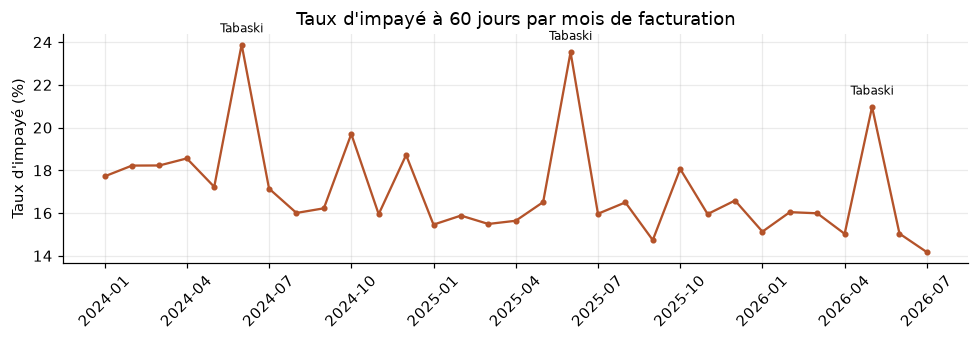

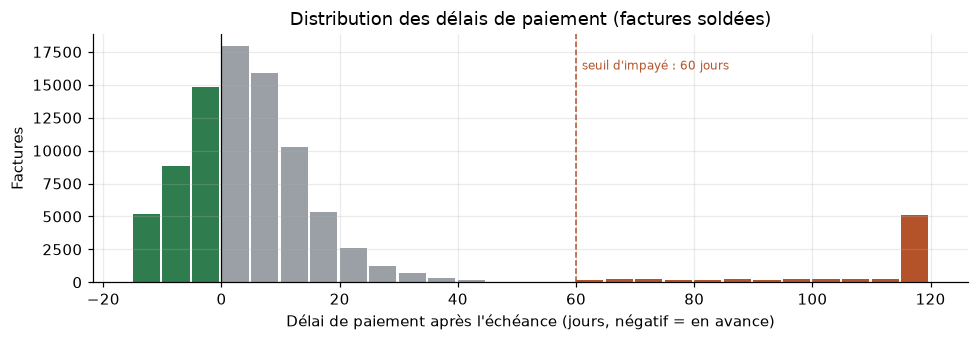

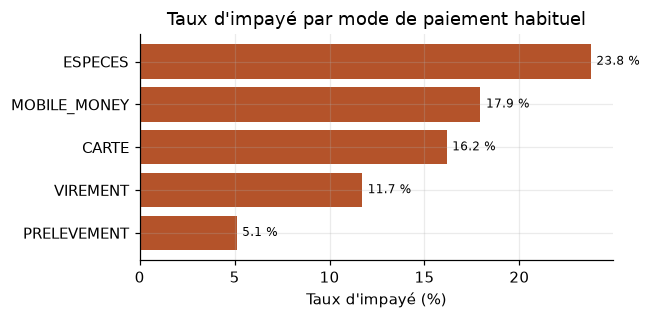

In [3]:
exploration = {
    "taux_impaye_mensuel": connues.assign(y=connues["risque_impaye"].astype(int)).groupby("periode")["y"].mean().to_dict(),
    "histogramme_delais": np.histogram(factures["delai_paiement_jours"].dropna().astype(float).clip(-15, 120),
                                       bins=np.arange(-15, 125, 5))[0].tolist(),
    "taux_impaye_par_mode": connues.merge(comptes, on="id_compte").assign(y=lambda d: d["risque_impaye"].astype(int))
                                   .groupby("mode_paiement")["y"].mean().to_dict(),
}
fig.fig_taux_mensuel(exploration); fig.fig_delais(exploration); fig.fig_par_mode(exploration); plt.show()

**Lecture** : pics d'impayés les mois de Tabaski (dépenses familiales) et à la rentrée ; le prélèvement
automatique protège nettement ; la plupart des factures sont payées autour de l'échéance, avec une longue traîne.

## 2. Variables explicatives, sans fuite d'information
Chaque variable est calculée **à la date d'émission** de la facture, avec ce qu'on savait ce jour-là.
Une facture précédente payée *après* cette date est vue comme « encore impayée » : c'est ce qu'aurait vu
l'équipe de recouvrement. Utiliser le solde final serait une fuite qui gonflerait artificiellement les scores.

In [4]:
d = ent.charger()
print(f"{len(prep.VARIABLES)} variables : {len(prep.CATEGORIELLES)} catégorielles, {len(prep.NUMERIQUES)} numériques")
d[prep.NUMERIQUES].describe().T[["mean", "50%", "min", "max"]]

23 variables : 5 catégorielles, 18 numériques


,mean,50%,min,max
nb_lignes,2.4990,2.0000,1.0000,20.0000
contact_valide,0.8882,1.0000,0.0000,1.0000
anciennete_mois,42.6714,38.1000,1.0000,138.6000
mois_emission,6.3166,6.0000,1.0000,12.0000
montant,"28,821.7396","17,700.0000","3,300.0000","981,500.0000"
ratio_montant_6m,1.0124,0.9833,0.2478,3.6650
nb_factures_passees,12.9639,12.0000,0.0000,32.0000
retard_moyen_6m,14.4251,9.0000,-15.0000,92.5000
retard_max_6m,49.7627,16.0000,-15.0000,169.0000
retard_derniere_facture,4.9363,5.0000,-15.0000,16.0000


## 3. Découpage temporel
On apprend sur le passé et on teste sur des mois jamais vus, comme en production. Un découpage aléatoire
mélangerait les mois et surestimerait la performance.

In [5]:
j = ent.decouper(d)
app, val, test = j["apprentissage"], j["validation"], j["test"]
pd.DataFrame({k: {"factures": len(v), "de": v["periode"].min(), "à": v["periode"].max(),
                  "taux_impaye": v[ent.CIBLE].astype(float).mean()} for k, v in j.items()}).T

,factures,de,à,taux_impaye
apprentissage,72823,2024-01,2025-11,0.1749
validation,8718,2025-12,2026-02,0.1592
test,14050,2026-03,2026-07,0.1626
a_scorer,5294,2026-08,2026-09,NaN


## 4. Modèles
1. **Règle métier** : pire retard récent + nombre d'impayés en cours (ce que ferait un analyste sans modèle).
2. **Régression logistique** : référence statistique.
3. **LightGBM** : gradient boosting sur arbres, petite recherche en grille jugée sur la **validation** uniquement.

On ajoute un **oracle** : la vraie probabilité du simulateur, inaccessible dans un vrai projet,
qui donne le plafond atteignable avec ces données.

In [6]:
logistique = ent.entrainer_logistique(app)
lgbm, grille = ent.regler_lightgbm(app, val)
pd.DataFrame(grille).sort_values("auc_validation", ascending=False).head()

,num_leaves,min_child_samples,nb_arbres,auc_validation
7,31,200,213,0.7302
3,15,50,206,0.7301
4,15,200,237,0.7300
8,31,500,157,0.7299
6,31,50,140,0.7295


In [7]:
y = test[ent.CIBLE].to_numpy()
scores = {"Règle métier": ent.score_regle(test),
          "Régression logistique": logistique.predict_proba(test[prep.VARIABLES])[:, 1],
          "LightGBM": lgbm.predict(test[prep.VARIABLES], num_iteration=lgbm.best_iteration)}
verite = pd.read_csv("../data/verite_cachee.csv").set_index("id_facture")["proba_reelle"]
tableau = {nom: ent.metriques(y, s, proba=(nom != "Règle métier")) for nom, s in scores.items()}
tableau["Oracle (plafond)"] = ent.metriques(y, verite.loc[test["id_facture"]].to_numpy())
pd.DataFrame(tableau).T[["auc", "pr_auc", "gini", "ks", "lift_top10", "rappel_top20", "brier"]]

,auc,pr_auc,gini,ks,lift_top10,rappel_top20,brier
Règle métier,0.6501,0.2798,0.3001,0.2146,2.1322,0.3551,NaN
Régression logistique,0.7277,0.3632,0.4554,0.3310,2.7102,0.4492,0.1217
LightGBM,0.7253,0.3636,0.4505,0.3278,2.7539,0.4518,0.1216
Oracle (plafond),0.7966,0.5172,0.5932,0.4428,3.7040,0.5512,0.1060


**Lecture honnête** : les deux modèles battent nettement la règle métier, mais LightGBM et la régression
logistique font **jeu égal**. L'écart restant avec l'oracle vient surtout de difficultés soudaines (perte de revenu,
dépense imprévue) qu'aucun historique de paiement ne peut annoncer : il faudrait d'autres sources (recharges,
usage, réclamations). À performance égale, LightGBM est retenu pour ses explications par facture (SHAP),
sa gestion native des valeurs manquantes et des catégories, et parce qu'il absorbera mieux de futures variables
non linéaires ; la régression logistique reste une alternative crédible, plus simple à auditer.

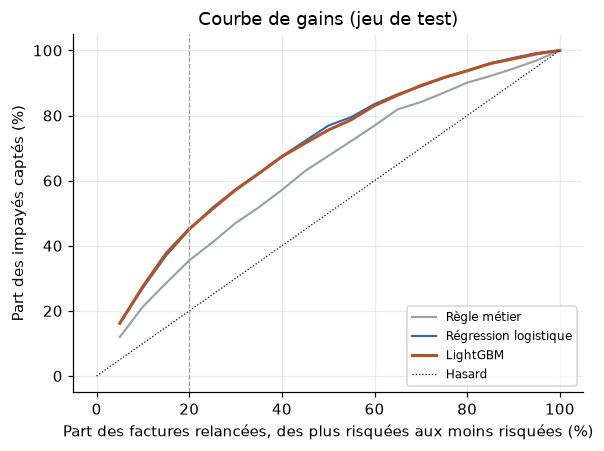

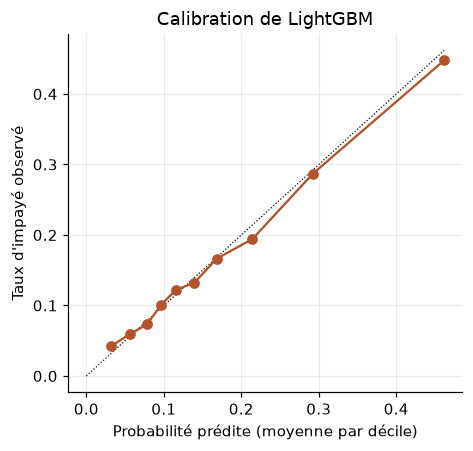

In [8]:
resultats = {"gains": {nom: ent.courbe_gains(y, s) for nom, s in scores.items()},
             "calibration": ent.calibration(y, scores["LightGBM"])}
fig.fig_gains(resultats); fig.fig_calibration(resultats); plt.show()

## 5. Interprétation (SHAP)
LightGBM calcule nativement les valeurs SHAP (`pred_contrib=True`) : la contribution de chaque variable
au score de **chaque** facture. C'est ce qui permet d'expliquer une relance à un client ou à un agent.

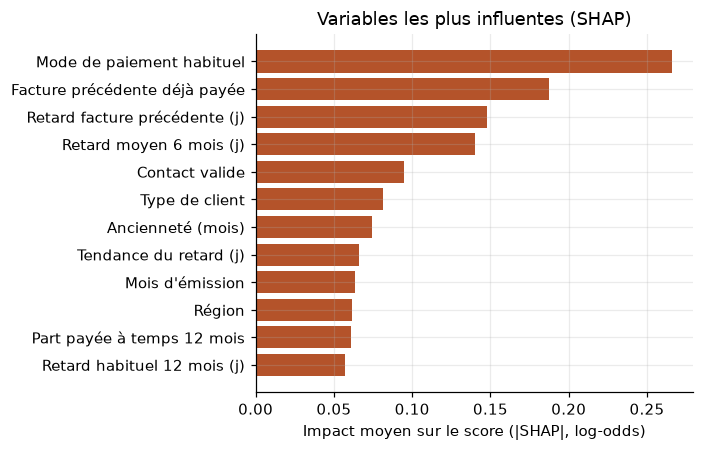

,variable,libelle,shap_moyen_abs
3,mode_paiement,Mode de paiement habituel,0.2661
19,derniere_facture_payee,Facture précédente déjà payée,0.1872
14,retard_derniere_facture,Retard facture précédente (j),0.1479
12,retard_moyen_6m,Retard moyen 6 mois (j),0.1398
6,contact_valide,Contact valide,0.0947
0,type_client,Type de client,0.0814
7,anciennete_mois,Ancienneté (mois),0.0744
15,tendance_retard,Tendance du retard (j),0.0660
8,mois_emission,Mois d'émission,0.0635
1,region,Région,0.0618


In [9]:
shap = ent.importance_shap(lgbm, test)
fig.fig_importance({"importance": shap.to_dict(orient="records")}); plt.show()
shap.head(10)

In [10]:
# Explication d'une facture à risque élevé
proba = scores["LightGBM"]
i = int(np.argsort(proba)[-50])
ligne = test.iloc[[i]]
contrib = lgbm.predict(ligne[prep.VARIABLES], num_iteration=lgbm.best_iteration, pred_contrib=True)[0]
print(f"Probabilité d'impayé : {proba[i]:.1%} (issue réelle : {int(ligne[ent.CIBLE].iloc[0])})")
pd.DataFrame({"valeur": ligne[prep.VARIABLES].iloc[0].astype(str).to_numpy(), "contribution": contrib[:-1]},
             index=[ent.LIBELLES[v] for v in prep.VARIABLES]).sort_values("contribution", key=abs, ascending=False).head(8)

Probabilité d'impayé : 64.8% (issue réelle : 1)


,valeur,contribution
Retard moyen 6 mois (j),77.67,0.5834
Facture précédente déjà payée,0.0,0.4600
Contact valide,0,0.3803
Retard facture précédente (j),16.0,0.2769
Factures impayées en cours,13,0.2462
Retard habituel 12 mois (j),28.0,0.2366
Mode de paiement habituel,MOBILE_MONEY,0.1219
Part payée à temps 12 mois,0.0,0.0715


## 6. Valeur pour le recouvrement
L'équipe peut relancer 20 % des factures chaque mois. Quel ciblage évite le plus d'impayés ?
*Hypothèse explicite* : une relance évite 35 % des impayés qu'elle cible. Ce chiffre doit être **mesuré par un
test A/B** (groupe témoin non relancé) avant toute décision.

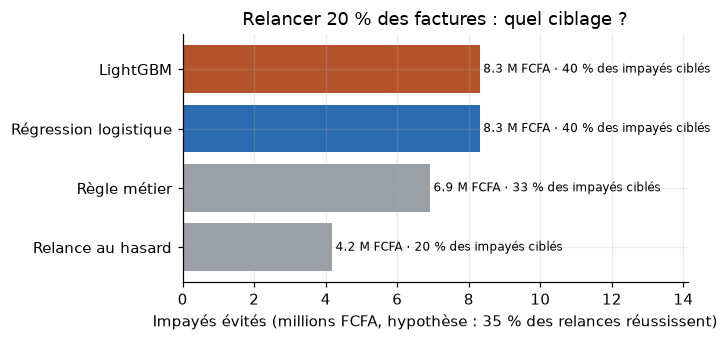

,strategie,factures_relancees,impayes_captes_pct,montant_evite_fcfa
0,Relance au hasard,2807,20.0000,4174631
1,Règle métier,2807,33.1000,6912395
2,Régression logistique,2807,39.8000,8304974
3,LightGBM,2807,39.8000,8303819


In [11]:
simulation = ent.simulation_relance(test, scores)
fig.fig_simulation({"simulation_relance": simulation}); plt.show()
pd.DataFrame(simulation)

## 7. Conclusions et suites
- Cibler les relances avec le modèle double environ la part d'impayés atteinte par rapport au hasard,
  et fait mieux que la règle métier.
- Variables décisives : mode de paiement, statut et retard de la facture précédente, régularité passée, validité du contact
  (une facture envoyée par SMS à un numéro invalide n'arrive jamais : action corrective simple et peu coûteuse).
- **Suites** : test A/B des relances ciblées ; modèle de *survie* pour prédire la date probable de paiement
  (trésorerie) ; modèle d'*uplift* pour cibler les clients sensibles à une relance ; nouvelles sources (recharges, usage) ;
  suivi mensuel de la dérive et recalibrage.